# **Notebook 5: Model Evaluation, Comparison, and Selection**

### **Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import os
import json, joblib
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score
)
from itertools import combinations

### **Model selection using training cross-validation**

In [2]:
PROJECT_ROOT = Path.cwd()
OUT_DIR = PROJECT_ROOT / "NB_OUTS1_TRAINONLY"

assert (
    (OUT_DIR / "NB4_training_cv_summary.csv").exists()
    or (OUT_DIR / "NB4_training_only_ranking.csv").exists()
), "NB4 outputs not found. Run NB4 first."

summary_path = OUT_DIR / 'NB4_training_cv_summary.csv'
if summary_path.exists():
    cv_summary = pd.read_csv(summary_path)
else:
    # Prior NB4 runs saved the same CV metrics together with their ranking.
    cv_summary = pd.read_csv(OUT_DIR / 'NB4_training_only_ranking.csv')

models = ['LR_baseline', 'LR_tuned', 'RF_baseline', 'RF_tuned', 'ANN_baseline', 'ANN_tuned']
criteria = ['cv_recall', 'cv_auc', 'cv_balanced_accuracy', 'cv_recall_gap']
required_cols = ['model', 'threshold'] + criteria
missing = [col for col in required_cols if col not in cv_summary.columns]
if missing:
    raise ValueError(f'Missing CV summary columns: {missing}')
if len(cv_summary) != 6 or set(cv_summary['model']) != set(models):
    raise ValueError('Expected one cross-validation summary row for each of the six models.')
if cv_summary[required_cols[1:]].isna().any().any():
    raise ValueError('Missing threshold or CV metric in model-selection inputs.')

ranking = cv_summary[['model', 'threshold'] + criteria].copy()
for metric, rank_col, higher_is_better in [
    ('cv_recall', 'rank_recall', True),
    ('cv_auc', 'rank_auc', True),
    ('cv_balanced_accuracy', 'rank_bal_acc', True),
    ('cv_recall_gap', 'rank_gap', False),
]:
    ranking[rank_col] = ranking[metric].round(6).rank(
        method='min', ascending=not higher_is_better
    ).astype(int)

ranking['total_score'] = ranking[
    ['rank_recall', 'rank_auc', 'rank_bal_acc', 'rank_gap']
].sum(axis=1)
ranking = ranking.sort_values(
    ['total_score', 'cv_recall', 'cv_auc', 'model'],
    ascending=[True, False, False, True]
).reset_index(drop=True)
SELECTED_MODEL = str(ranking.loc[0, 'model'])
ranking['selected'] = ranking['model'].eq(SELECTED_MODEL)
thresholds = dict(zip(ranking['model'], ranking['threshold'].astype(float)))

selection_info = {
    'selected_model': SELECTED_MODEL,
    'selection_source': 'training 5-fold cross-validation',
    'eligible_models': models,
    'criteria': criteria,
    'winner_threshold': float(thresholds[SELECTED_MODEL]),
    'seed': 42,
}
ranking.to_csv(OUT_DIR / 'NB5_training_only_ranking.csv', index=False)
with open(OUT_DIR / 'NB5_model_selection.json', 'w') as file:
    json.dump(selection_info, file, indent=2)

print('=== MODEL RANKING (TRAINING CV) ===')
print(ranking[['model','threshold','cv_recall','cv_auc','cv_balanced_accuracy','cv_recall_gap','total_score']].round(3).to_string(index=False))
print('Selected model:', SELECTED_MODEL)
print('Threshold:', f'{thresholds[SELECTED_MODEL]:.2f}')

=== MODEL RANKING (TRAINING CV) ===
       model  threshold  cv_recall  cv_auc  cv_balanced_accuracy  cv_recall_gap  total_score
    RF_tuned       0.44      0.782   0.771                 0.715          0.079            7
    LR_tuned       0.36      0.808   0.765                 0.732          0.131            8
   ANN_tuned       0.25      0.641   0.706                 0.691          0.346           16
 LR_baseline       0.50      0.538   0.740                 0.684          0.308           16
ANN_baseline       0.50      0.385   0.768                 0.649          0.612           18
 RF_baseline       0.50      0.256   0.799                 0.603          0.741           19
Selected model: RF_tuned
Threshold: 0.44


### **Test-set evaluation data**

In [3]:
family_files={
 'LR':('NB3_LR_lasso_train.csv','NB3_LR_lasso_test.csv'),
 'RF':('NB3_RandomForest_train.csv','NB3_RandomForest_test.csv'),
 'ANN':('NB3_ANN_train.csv','NB3_ANN_test.csv')}
family_frames={}
for fam,(trname,tename) in family_files.items():
    tr=pd.read_csv(OUT_DIR/trname,index_col='orig_index')
    te=pd.read_csv(OUT_DIR/tename,index_col='orig_index')
    family_frames[fam]=(tr,te)
for fam in ['RF','ANN']:
    assert family_frames[fam][0]['depressed_flag'].equals(family_frames['LR'][0]['depressed_flag'])
    assert family_frames[fam][1]['depressed_flag'].equals(family_frames['LR'][1]['depressed_flag'])
base_train,base_test=family_frames['LR']
train_df=pd.DataFrame({'original_idx':base_train.index,'split':'train','y_true':base_train['depressed_flag'].to_numpy()})
test_df=pd.DataFrame({'original_idx':base_test.index,'split':'test','y_true':base_test['depressed_flag'].to_numpy()})
assert len(train_df)==530 and len(test_df)==133
for name in models:
    family=name.split('_')[0]
    tr,te=family_frames[family]
    features=[c for c in tr.columns if c!='depressed_flag']
    model=joblib.load(OUT_DIR/f'NB4_fitted_{name}.joblib')
    for df,destin in [(tr,train_df),(te,test_df)]:
        prob=model.predict_proba(df[features])[:,1]
        destin[name+'_proba']=prob
        destin[name+'_pred']=(prob>=thresholds[name]).astype(int)
combined_df=pd.concat([train_df,test_df],ignore_index=True)
combined_df.to_csv(OUT_DIR / 'NB5_combined_predictions.csv', index=False)
print('Saved NB5_combined_predictions.csv')
print('Train/Test:',train_df.shape,test_df.shape)

Saved NB5_combined_predictions.csv
Train/Test: (530, 15) (133, 15)


### **Metric definitions**

Recall, specificity, precision, AUC, balanced accuracy, F1, and the confusion matrix are reported for each model. The false-negative rate is one minus recall.

### **Evaluation metrics**

In [4]:
def compute_metrics(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    recall      = recall_score(y_true, y_pred, zero_division=0)
    fnr         = fn / (fn + tp) if (fn + tp) > 0 else np.nan   # = 1 - recall

    if min(tp, tn, fp, fn) == 0:
        odds_ratio = ((tp + 0.5) * (tn + 0.5)) / ((fp + 0.5) * (fn + 0.5))
    else:
        odds_ratio = (tp * tn) / (fp * fn)

    return {
        'balanced_accuracy':   balanced_accuracy_score(y_true, y_pred),
        'accuracy':            accuracy_score(y_true, y_pred),
        'precision':           precision_score(y_true, y_pred, zero_division=0),
        'recall_sensitivity':  recall,
        'specificity':         specificity,
        'false_positive_rate': fp / (fp + tn) if (fp + tn) > 0 else np.nan,
        'false_negative_rate': fnr,
        'f1_score':            f1_score(y_true, y_pred, zero_division=0),
        'auc':                 roc_auc_score(y_true, y_proba),
        'odds_ratio':          odds_ratio,
        'TP': int(tp), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn),
    }

long_rows = []
for model in models:
    for split_name, df_split in [('train', train_df), ('test', test_df)]:
        m = compute_metrics(df_split['y_true'], df_split[f'{model}_pred'], df_split[f'{model}_proba'])
        long_rows.append({'model': model, 'split': split_name, **m})
metrics_long_df = pd.DataFrame(long_rows)

wide_rows = []
for model in models:
    train_m = compute_metrics(train_df['y_true'], train_df[f'{model}_pred'], train_df[f'{model}_proba'])
    test_m  = compute_metrics(test_df['y_true'],  test_df[f'{model}_pred'],  test_df[f'{model}_proba'])
    row = {'model': model}
    for k, v in train_m.items(): row[f'train_{k}'] = v
    for k, v in test_m.items():  row[f'test_{k}'] = v
    wide_rows.append(row)
metrics_wide_df = pd.DataFrame(wide_rows)

display_cols = ['model', 'split', 'balanced_accuracy', 'accuracy', 'precision',
                'recall_sensitivity', 'specificity', 'false_negative_rate',
                'f1_score', 'auc', 'odds_ratio']
print("=== Per-Model, Per-Split Metrics (FNR and Odds Ratio included) ===")
print(metrics_long_df[display_cols].round(3).to_string(index=False))

=== Per-Model, Per-Split Metrics (FNR and Odds Ratio included) ===
       model split  balanced_accuracy  accuracy  precision  recall_sensitivity  specificity  false_negative_rate  f1_score   auc  odds_ratio
 LR_baseline train              0.864     0.849      0.493               0.885        0.843                0.115     0.633 0.922      41.141
 LR_baseline  test              0.768     0.789      0.378               0.737        0.798                0.263     0.500 0.847      11.078
    LR_tuned train              0.822     0.732      0.349               0.949        0.695                0.051     0.510 0.916      42.094
    LR_tuned  test              0.785     0.707      0.315               0.895        0.675                0.105     0.466 0.849      17.689
 RF_baseline train              1.000     1.000      1.000               1.000        1.000                0.000     1.000 1.000  142085.000
 RF_baseline  test              0.627     0.850      0.462               0.316        0

### **Train-test differences**

In [5]:
gap_metrics = ['balanced_accuracy', 'accuracy', 'precision', 'recall_sensitivity', 'f1_score', 'auc']
for metric in gap_metrics:
    metrics_wide_df[f'{metric}_gap'] = (
        metrics_wide_df[f'train_{metric}'] - metrics_wide_df[f'test_{metric}']).abs()

gap_cols = ['model'] + [f'{m}_gap' for m in gap_metrics]
print("=== Train/Test Gaps (smaller = less overfitting) ===")
print(metrics_wide_df[gap_cols].round(3).to_string(index=False))

=== Train/Test Gaps (smaller = less overfitting) ===
       model  balanced_accuracy_gap  accuracy_gap  precision_gap  recall_sensitivity_gap  f1_score_gap  auc_gap
 LR_baseline                  0.096         0.060          0.114                   0.148         0.133    0.075
    LR_tuned                  0.037         0.025          0.034                   0.054         0.045    0.066
 RF_baseline                  0.373         0.150          0.538                   0.684         0.625    0.160
    RF_tuned                  0.009         0.024          0.003                   0.057         0.005    0.011
ANN_baseline                  0.325         0.143          0.500                   0.579         0.543    0.248
   ANN_tuned                  0.318         0.169          0.429                   0.526         0.474    0.265


### **ROC curves**

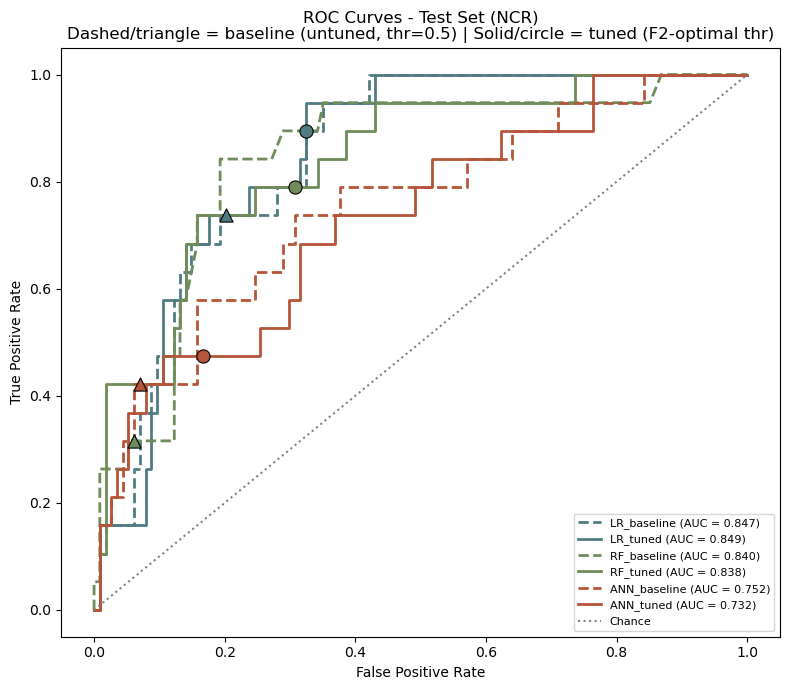

Saved: NB5_ROC_curves.png


In [6]:
color_map = {
    'LR_baseline': '#4F7C82', 'LR_tuned': '#4F7C82',
    'RF_baseline': '#6F8C5A', 'RF_tuned': '#6F8C5A',
    'ANN_baseline': '#B5553A', 'ANN_tuned': '#B5553A',
}
style_map  = {m: ('--' if 'baseline' in m else '-') for m in models}
marker_map = {m: ('^' if 'baseline' in m else 'o') for m in models}

fig, ax = plt.subplots(figsize=(8, 7))
for model in models:
    color, ls, mk = color_map[model], style_map[model], marker_map[model]
    fpr, tpr, _ = roc_curve(test_df['y_true'], test_df[f'{model}_proba'])
    auc_val = roc_auc_score(test_df['y_true'], test_df[f'{model}_proba'])
    ax.plot(fpr, tpr, label=f'{model} (AUC = {auc_val:.3f})', color=color, linestyle=ls, linewidth=2)
    tn, fp, fn, tp = confusion_matrix(test_df['y_true'], test_df[f'{model}_pred']).ravel()
    ax.scatter(fp/(fp+tn), tp/(tp+fn), color=color, s=90, zorder=5,
               edgecolors='black', linewidths=0.8, marker=mk)

ax.plot([0, 1], [0, 1], linestyle=':', color='gray', label='Chance')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves - Test Set (NCR)\n'
             'Dashed/triangle = baseline (untuned, thr=0.5) | Solid/circle = tuned (F2-optimal thr)')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "NB5_ROC_curves.png"), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: NB5_ROC_curves.png")

### **Confusion matrices**

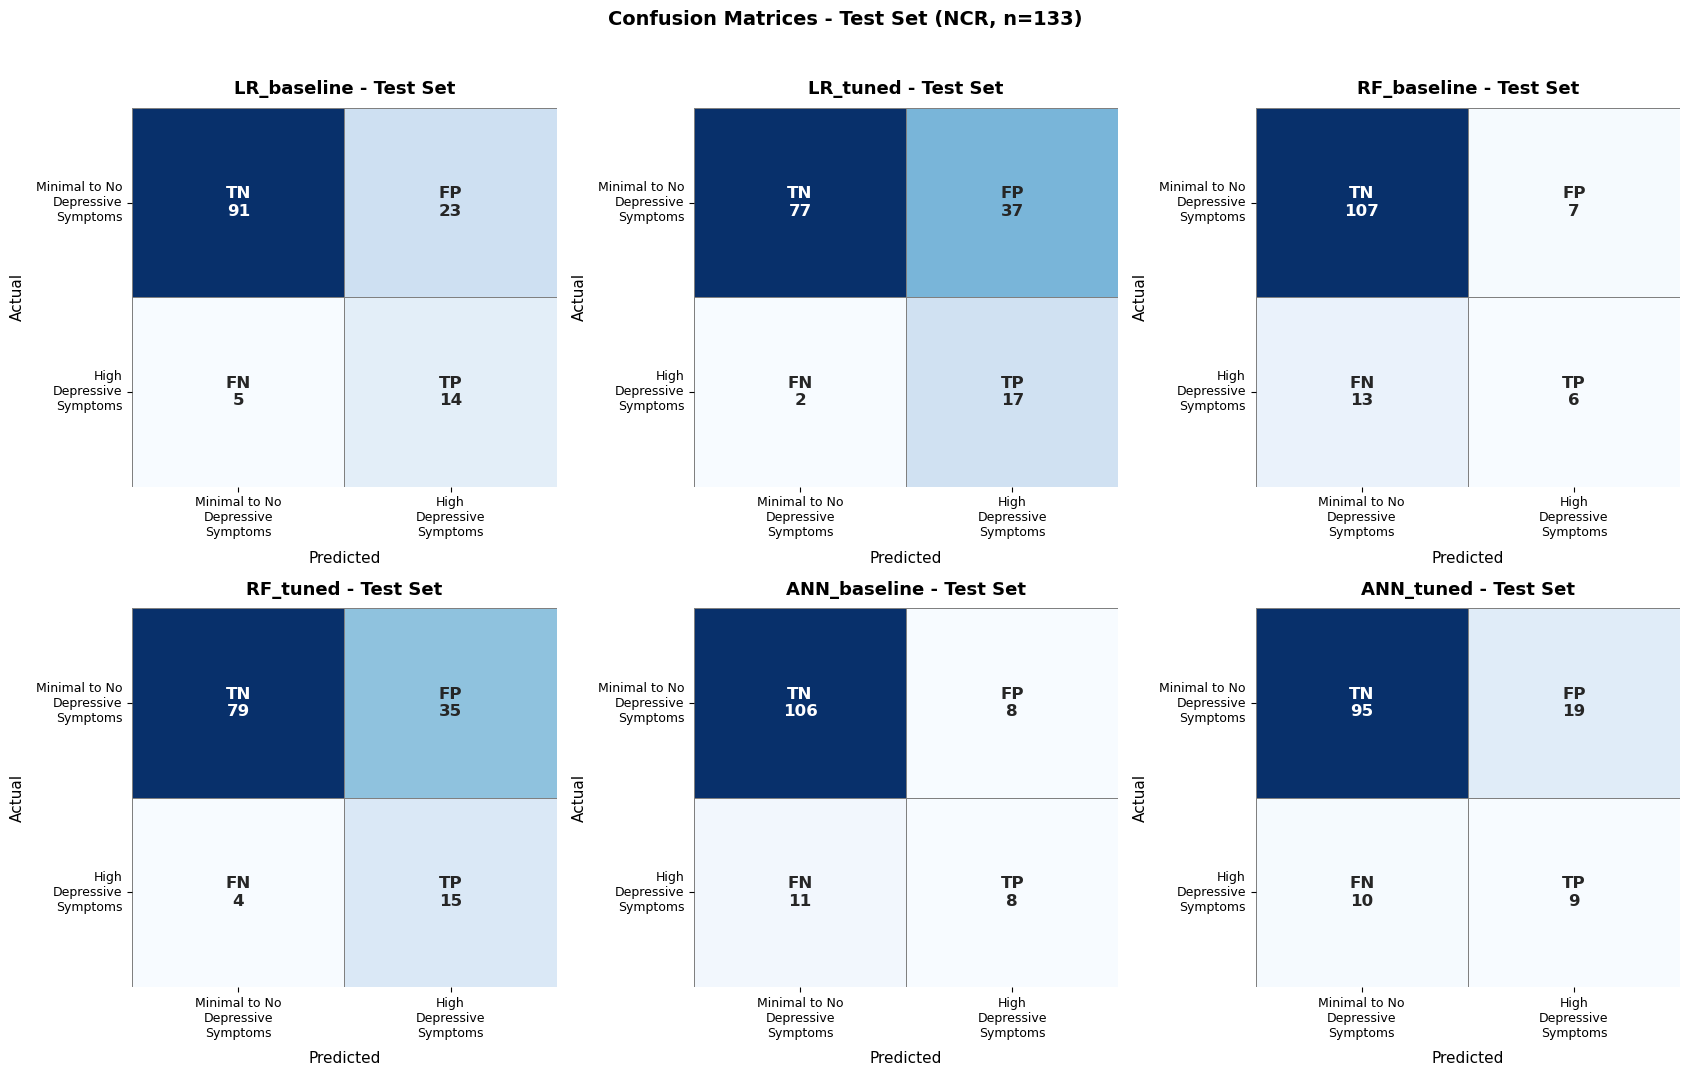

Saved: NB5_confusion_matrices.png


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
axes = axes.flatten()

for ax, model in zip(axes, models):
    cm = confusion_matrix(test_df['y_true'], test_df[f'{model}_pred'])
    tn, fp, fn, tp = cm.ravel()

    annot = np.array([
        [f'TN\n{tn}', f'FP\n{fp}'],
        [f'FN\n{fn}', f'TP\n{tp}']
    ])

    sns.heatmap(
        cm, annot=annot, fmt='', cmap='Blues',
        xticklabels=['Minimal to No\nDepressive\nSymptoms', 'High\nDepressive\nSymptoms'],
        yticklabels=['Minimal to No\nDepressive\nSymptoms', 'High\nDepressive\nSymptoms'],
        ax=ax, cbar=False,
        linewidths=0.5, linecolor='gray',
        annot_kws={'size': 12, 'weight': 'bold'}
    )
    ax.set_title(f'{model} - Test Set', fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel('Predicted', fontsize=11, labelpad=8)
    ax.set_ylabel('Actual', fontsize=11, labelpad=8)
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=9, ha='center')
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=9, va='center', rotation=0)

fig.suptitle(f'Confusion Matrices - Test Set (NCR, n={len(test_df)})', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "NB5_confusion_matrices.png"), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: NB5_confusion_matrices.png")

### **Confusion matrix breakdown**

In [8]:
print("=" * 68)
print(f"CONFUSION MATRIX BREAKDOWN - TEST SET (n={len(test_df)})")
print("=" * 68)

breakdown_records = []

for model in models:
    tn, fp, fn, tp = confusion_matrix(test_df['y_true'], test_df[f'{model}_pred']).ravel()

    total       = tp + tn + fp + fn
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0      # recall
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    fnr         = fn / (fn + tp) if (fn + tp) > 0 else 0      # 1 - recall
    if min(tp, tn, fp, fn) == 0:
        dor = ((tp + 0.5) * (tn + 0.5)) / ((fp + 0.5) * (fn + 0.5))
    else:
        dor = (tp * tn) / (fp * fn)

    breakdown_records.append({
        'Model'         : model,
        'TP'            : int(tp),
        'TN'            : int(tn),
        'FP'            : int(fp),
        'FN'            : int(fn),
        'Total'         : int(total),
        'Recall'        : round(sensitivity, 4),
        'Specificity'   : round(specificity, 4),
        'FNR'           : round(fnr, 4),
        'OddsRatio'     : round(dor, 4),
    })

    print(f"\n  {model}")
    print(f"  {'-'*50}")
    print(f"    True  Positives (TP) - correctly flagged HDS cases : {tp:>4}")
    print(f"    True  Negatives (TN) - correctly classified MNDS cases : {tn:>4}")
    print(f"    False Positives (FP) - wrongly flagged MNDS cases  : {fp:>4}")
    print(f"    False Negatives (FN) - missed true HDS cases       : {fn:>4}")
    print(f"    {'-'*50}")
    print(f"    Total test observations                            : {total:>4}")
    print(f"    Recall      = TP / (TP+FN)                         : {sensitivity:>7.4f}")
    print(f"    Specificity = TN / (TN+FP)                         : {specificity:>7.4f}")
    print(f"    FNR         = FN / (FN+TP)  (1 - recall)           : {fnr:>7.4f}")
    print(f"    Odds Ratio  = (TP*TN)/(FP*FN)                      : {dor:>7.4f}")

print(f"\n{'='*68}")

breakdown_df = pd.DataFrame(breakdown_records)
print(f"\n{'Model':<14} {'TP':>4} {'TN':>4} {'FP':>4} {'FN':>4} {'Total':>6} "
      f"{'Recall':>8} {'Spec':>8} {'FNR':>8} {'OddsR':>9}")
print("-" * 80)
for _, row in breakdown_df.iterrows():
    print(f"{row['Model']:<14} {row['TP']:>4} {row['TN']:>4} {row['FP']:>4} "
          f"{row['FN']:>4} {row['Total']:>6} {row['Recall']:>8.4f} "
          f"{row['Specificity']:>8.4f} {row['FNR']:>8.4f} {row['OddsRatio']:>9.4f}")

print("\nFNR is the headline screening error: the fraction of true HDS cases missed.")
print("Odds Ratio > 1 indicates better-than-chance discrimination; higher is better.")

breakdown_df.to_csv(os.path.join(OUT_DIR, "NB5_confusion_breakdown.csv"), index=False)
print(f"\nSaved: NB5_confusion_breakdown.csv")

CONFUSION MATRIX BREAKDOWN - TEST SET (n=133)

  LR_baseline
  --------------------------------------------------
    True  Positives (TP) - correctly flagged HDS cases :   14
    True  Negatives (TN) - correctly classified MNDS cases :   91
    False Positives (FP) - wrongly flagged MNDS cases  :   23
    False Negatives (FN) - missed true HDS cases       :    5
    --------------------------------------------------
    Total test observations                            :  133
    Recall      = TP / (TP+FN)                         :  0.7368
    Specificity = TN / (TN+FP)                         :  0.7982
    FNR         = FN / (FN+TP)  (1 - recall)           :  0.2632
    Odds Ratio  = (TP*TN)/(FP*FN)                      : 11.0783

  LR_tuned
  --------------------------------------------------
    True  Positives (TP) - correctly flagged HDS cases :   17
    True  Negatives (TN) - correctly classified MNDS cases :   77
    False Positives (FP) - wrongly flagged MNDS cases  :   37
  

### **Baseline and tuned model comparison**

In [9]:
# Baseline and tuned configurations
STAGE1_METRICS = [
    # (column in metrics_wide_df, label, higher_is_better)
    ('test_recall_sensitivity',  'Recall',      True),
    ('test_auc',                 'AUC',         True),
    ('test_balanced_accuracy',   'Bal.Acc',     True),
    ('recall_sensitivity_gap',   'Rec.Gap',     False),
    ('test_false_negative_rate', 'FNR',         False),
    ('test_specificity',         'Specificity', True),
    ('test_precision',           'Precision',   True),
    ('test_f1_score',            'F1',          True),
]
_m = metrics_wide_df.set_index('model')
_rows = []
for fam in ['LR', 'RF', 'ANN']:
    for col, label, higher_better in STAGE1_METRICS:
        b, t = float(_m.loc[f'{fam}_baseline', col]), float(_m.loc[f'{fam}_tuned', col])
        d = t - b
        verdict = 'unchanged' if abs(d) < 1e-6 else ('improved' if (d > 0) == higher_better else 'declined')
        _rows.append({'family': fam, 'metric': label, 'baseline': b, 'tuned': t,
                      'change': d, 'effect_of_tuning': verdict})
stage1_df = pd.DataFrame(_rows)

print("=" * 86)
print("STAGE 1 - BASELINE vs TUNED (test set; descriptive only)")
print("=" * 86)
for fam in ['LR', 'RF', 'ANN']:
    print(f"\n{fam}: {fam}_baseline -> {fam}_tuned")
    print(stage1_df[stage1_df['family'] == fam][['metric', 'baseline', 'tuned', 'change', 'effect_of_tuning']]
          .round(4).to_string(index=False))

stage1_df.to_csv(os.path.join(OUT_DIR, "NB5_stage1_baseline_vs_tuned.csv"), index=False)
print("\nSaved: NB5_stage1_baseline_vs_tuned.csv")

STAGE 1 - BASELINE vs TUNED (test set; descriptive only)

LR: LR_baseline -> LR_tuned
     metric  baseline  tuned  change effect_of_tuning
     Recall    0.7368 0.8947  0.1579         improved
        AUC    0.8472 0.8495  0.0023         improved
    Bal.Acc    0.7675 0.7851  0.0175         improved
    Rec.Gap    0.1478 0.0540 -0.0938         improved
        FNR    0.2632 0.1053 -0.1579         improved
Specificity    0.7982 0.6754 -0.1228         declined
  Precision    0.3784 0.3148 -0.0636         declined
         F1    0.5000 0.4658 -0.0342         declined

RF: RF_baseline -> RF_tuned
     metric  baseline  tuned  change effect_of_tuning
     Recall    0.3158 0.7895  0.4737         improved
        AUC    0.8396 0.8380 -0.0016         declined
    Bal.Acc    0.6272 0.7412  0.1140         improved
    Rec.Gap    0.6842 0.0567 -0.6275         improved
        FNR    0.6842 0.2105 -0.4737         improved
Specificity    0.9386 0.6930 -0.2456         declined
  Precision    0.4615

### **Model selection summary**

=== MODEL SELECTION SUMMARY ===
Selection criteria: training CV recall, AUC, balanced accuracy, and recall gap.

CROSS-VALIDATION METRICS
       Model   Thr  Recall   AUC  BalAcc   Gap  Total
    RF_tuned 0.440   0.782 0.771   0.715 0.079      7
    LR_tuned 0.360   0.808 0.765   0.732 0.131      8
   ANN_tuned 0.250   0.641 0.706   0.691 0.346     16
 LR_baseline 0.500   0.538 0.740   0.684 0.308     16
ANN_baseline 0.500   0.385 0.768   0.649 0.612     18
 RF_baseline 0.500   0.256 0.799   0.603 0.741     19

RANKS (LOWER TOTAL IS BETTER)
       Model  Recall  AUC  BalAcc  Gap  Total
    RF_tuned       2    2       2    1      7
    LR_tuned       1    4       1    2      8
   ANN_tuned       3    6       3    4     16
 LR_baseline       4    5       4    3     16
ANN_baseline       5    3       5    5     18
 RF_baseline       6    1       6    6     19

SELECTED MODEL: RF_tuned | Threshold: 0.44


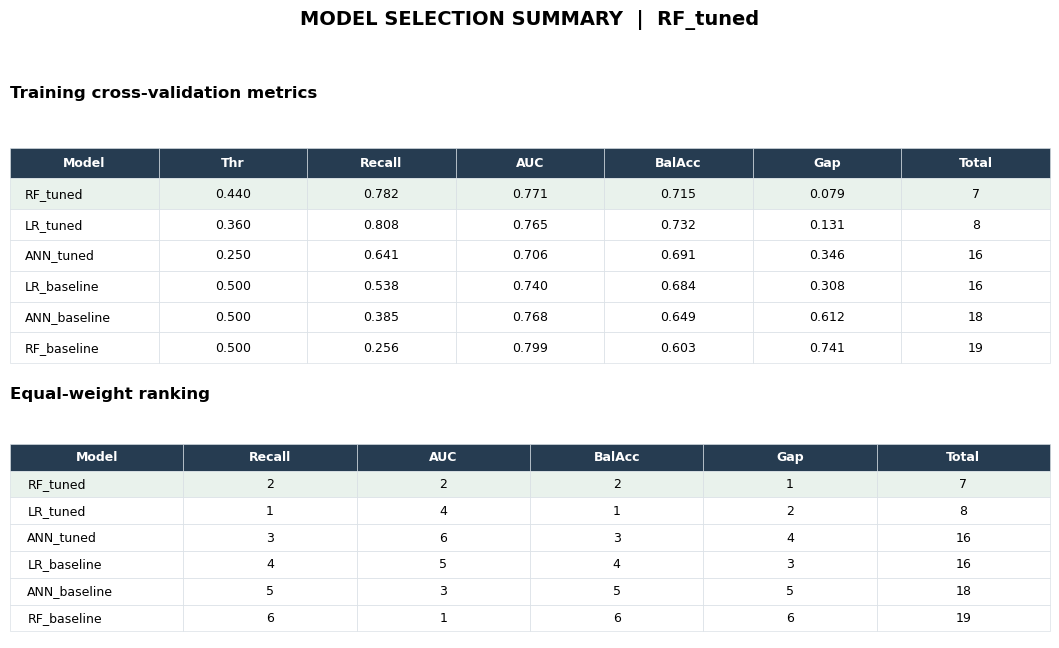

In [10]:
print('=== MODEL SELECTION SUMMARY ===')
print('Selection criteria: training CV recall, AUC, balanced accuracy, and recall gap.')

# Short column names keep the output readable at ordinary notebook width.
score_view = ranking[[
    'model','threshold','cv_recall','cv_auc','cv_balanced_accuracy',
    'cv_recall_gap','total_score'
]].rename(columns={
    'model':'Model', 'threshold':'Thr', 'cv_recall':'Recall',
    'cv_auc':'AUC','cv_balanced_accuracy':'BalAcc',
    'cv_recall_gap':'Gap','total_score':'Total'
})
print('\nCROSS-VALIDATION METRICS')
print(score_view.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

rank_view = ranking[[
    'model','rank_recall','rank_auc','rank_bal_acc','rank_gap','total_score'
]].rename(columns={
    'model':'Model', 'rank_recall':'Recall', 'rank_auc':'AUC',
    'rank_bal_acc':'BalAcc','rank_gap':'Gap','total_score':'Total'
})
print('\nRANKS (LOWER TOTAL IS BETTER)')
print(rank_view.to_string(index=False))
print(f'\nSELECTED MODEL: {SELECTED_MODEL} | Threshold: {thresholds[SELECTED_MODEL]:.2f}')

# Save one readable figure with the two tables.
fig, axes = plt.subplots(2, 1, figsize=(10.7, 6.5),
                         gridspec_kw={'height_ratios':[1.15,1]})
for ax, frame, heading in [
    (axes[0], score_view, 'Training cross-validation metrics'),
    (axes[1], rank_view, 'Equal-weight ranking')
]:
    ax.axis('off')
    ax.set_title(heading, fontsize=12, fontweight='bold', loc='left', pad=12)
    view = frame.copy()
    for column in view.columns:
        if pd.api.types.is_float_dtype(view[column]):
            view[column] = view[column].map(lambda x: f'{x:.3f}')
    cells = view.astype(str).values.tolist()
    colors = [['#E9F2EC' if name == SELECTED_MODEL else 'white'
               for _ in view.columns] for name in view['Model']]
    tb = ax.table(cellText=cells, colLabels=view.columns,
                  cellColours=colors, cellLoc='center',
                  colLoc='center', loc='center', bbox=[0,0.03,1,.84])
    tb.auto_set_font_size(False)
    tb.set_fontsize(9)
    for (r,c), cell in tb.get_celld().items():
        cell.set_linewidth(.45)
        cell.set_edgecolor('#D6DDE3')
        if r == 0:
            cell.set_facecolor('#263C51')
            cell.get_text().set_color('white')
            cell.get_text().set_weight('bold')
        elif c == 0:
            cell.get_text().set_ha('left')
fig.suptitle(f'MODEL SELECTION SUMMARY  |  {SELECTED_MODEL}',
             fontsize=14, weight='bold', y=.99)
fig.tight_layout(rect=(0,0,1,.95))
fig.savefig(OUT_DIR/'NB5_model_selection_summary.png', dpi=160,
            bbox_inches='tight')
plt.show()
plt.close(fig)

# Complete values are retained in the CSV files.
comparison_table = metrics_wide_df.copy()
comparison_table['selected'] = comparison_table['model'].eq(SELECTED_MODEL)
comparison_table['selection_source'] = 'training 5-fold CV'
comparison_table.to_csv(OUT_DIR/'NB5_model_comparison_table.csv', index=False)
ranking.to_csv(OUT_DIR/'NB5_stage2_ranking.csv', index=False)

### **Six-model performance comparison**

In [11]:
cv_part = ranking[['model','cv_recall','cv_auc','cv_balanced_accuracy','cv_recall_gap','total_score']]
test_part = metrics_wide_df[['model','test_recall_sensitivity','test_auc','test_balanced_accuracy',
                             'test_precision','test_specificity','recall_sensitivity_gap']]
comparison_full = cv_part.merge(test_part,on='model',validate='one_to_one')
print('=== TRAINING CV AND TEST COMPARISON (SIX MODELS) ===')
print('Training CV scores:')
print(comparison_full[['model','cv_recall','cv_auc','cv_balanced_accuracy','cv_recall_gap','total_score']].round(3).to_string(index=False))
print('Test performance (descriptive):')
print(comparison_full[['model','test_recall_sensitivity','test_auc','test_balanced_accuracy','test_precision','test_specificity']].round(3).to_string(index=False))
comparison_full.to_csv(OUT_DIR/'NB5_CV_and_test_model_comparison.csv',index=False)

print('\n=== TUNED MODEL COMPARISON (DESCRIPTIVE; NOT USED TO RESELECT) ===')
print(comparison_full.loc[comparison_full['model'].str.endswith('_tuned'),['model','test_recall_sensitivity','test_auc','test_balanced_accuracy','test_precision','test_specificity']].round(3).to_string(index=False))

=== TRAINING CV AND TEST COMPARISON (SIX MODELS) ===
Training CV scores:
       model  cv_recall  cv_auc  cv_balanced_accuracy  cv_recall_gap  total_score
    RF_tuned      0.782   0.771                 0.715          0.079            7
    LR_tuned      0.808   0.765                 0.732          0.131            8
   ANN_tuned      0.641   0.706                 0.691          0.346           16
 LR_baseline      0.538   0.740                 0.684          0.308           16
ANN_baseline      0.385   0.768                 0.649          0.612           18
 RF_baseline      0.256   0.799                 0.603          0.741           19
Test performance (descriptive):
       model  test_recall_sensitivity  test_auc  test_balanced_accuracy  test_precision  test_specificity
    RF_tuned                    0.789     0.838                   0.741           0.300             0.693
    LR_tuned                    0.895     0.849                   0.785           0.315             0.675
   

### **Bootstrap confidence intervals**

In [12]:
N_CI_BOOTSTRAPS  = 1000
rng              = np.random.RandomState(42)
n_test           = len(test_df)
ci_metric_names  = ['balanced_accuracy', 'accuracy', 'precision',
                    'recall_sensitivity', 'specificity',
                    'false_positive_rate', 'false_negative_rate',
                    'f1_score', 'auc', 'odds_ratio']
ci_records       = {model: {m: [] for m in ci_metric_names} for model in models}

for b in range(N_CI_BOOTSTRAPS):
    boot_idx    = rng.choice(n_test, size=n_test, replace=True)
    boot_y_true = test_df['y_true'].iloc[boot_idx].values
    if len(np.unique(boot_y_true)) < 2:
        continue
    for model in models:
        boot_pred  = test_df[f'{model}_pred'].iloc[boot_idx].values
        boot_proba = test_df[f'{model}_proba'].iloc[boot_idx].values
        m = compute_metrics(boot_y_true, boot_pred, boot_proba)
        for name in ci_metric_names:
            ci_records[model][name].append(m[name])

ci_rows = []
for model in models:
    row = {'model': model}
    for name in ci_metric_names:
        vals = np.array(ci_records[model][name], dtype=float)
        row[f'{name}_point']    = metrics_wide_df.loc[metrics_wide_df['model']==model, f'test_{name}'].values[0]
        row[f'{name}_ci_lower'] = np.nanpercentile(vals, 2.5)
        row[f'{name}_ci_upper'] = np.nanpercentile(vals, 97.5)
    ci_rows.append(row)

ci_df = pd.DataFrame(ci_rows)

print("=== 95% Bootstrap Confidence Intervals (Test Set) ===")
for model in models:
    row = ci_df[ci_df['model'] == model].iloc[0]
    print(f"\n{model}:")
    for name in ci_metric_names:
        pt = row[f'{name}_point']
        lo = row[f'{name}_ci_lower']
        hi = row[f'{name}_ci_upper']
        print(f"  {name:<22}: {pt:.3f}  (95% CI: {lo:.3f} to {hi:.3f})")

ci_df.to_csv(os.path.join(OUT_DIR, "NB5_bootstrap_confidence_intervals.csv"), index=False)
print("\nSaved: NB5_bootstrap_confidence_intervals.csv")

=== 95% Bootstrap Confidence Intervals (Test Set) ===

LR_baseline:
  balanced_accuracy     : 0.768  (95% CI: 0.655 to 0.865)
  accuracy              : 0.789  (95% CI: 0.714 to 0.857)
  precision             : 0.378  (95% CI: 0.222 to 0.556)
  recall_sensitivity    : 0.737  (95% CI: 0.533 to 0.917)
  specificity           : 0.798  (95% CI: 0.717 to 0.873)
  false_positive_rate   : 0.202  (95% CI: 0.127 to 0.283)
  false_negative_rate   : 0.263  (95% CI: 0.083 to 0.467)
  f1_score              : 0.500  (95% CI: 0.326 to 0.667)
  auc                   : 0.847  (95% CI: 0.770 to 0.916)
  odds_ratio            : 11.078  (95% CI: 4.050 to 49.587)

LR_tuned:
  balanced_accuracy     : 0.785  (95% CI: 0.696 to 0.862)
  accuracy              : 0.707  (95% CI: 0.624 to 0.782)
  precision             : 0.315  (95% CI: 0.186 to 0.447)
  recall_sensitivity    : 0.895  (95% CI: 0.737 to 1.000)
  specificity           : 0.675  (95% CI: 0.583 to 0.761)
  false_positive_rate   : 0.325  (95% CI: 0.239 t

### **Test model cards**

In [13]:
cards=[]
for name in models:
    r=metrics_wide_df.set_index('model').loc[name]
    ci=ci_df.set_index('model').loc[name]
    card={'model':name,'selected_using_CV':name==SELECTED_MODEL,
          'threshold':thresholds[name],
          'n_test':len(test_df),'TP':int(r['test_TP']),'TN':int(r['test_TN']),
          'FP':int(r['test_FP']),'FN':int(r['test_FN']),
          'recall':r['test_recall_sensitivity'],
          'recall_CI_low':ci['recall_sensitivity_ci_lower'],
          'recall_CI_high':ci['recall_sensitivity_ci_upper'],
          'AUC':r['test_auc'],'AUC_CI_low':ci['auc_ci_lower'],
          'AUC_CI_high':ci['auc_ci_upper'],
          'balanced_accuracy':r['test_balanced_accuracy'],
          'precision':r['test_precision'],
          'specificity':r['test_specificity'],
          'train_test_recall_gap':r['recall_sensitivity_gap']}
    cards.append(card)
    print('\n'+'='*64)
    print(f'{name.upper()} | TEST MODEL CARD')
    print('='*64)
    for label,value in card.items():
        print(f'  {label:<26}: {value:.4f}' if isinstance(value,(float,np.floating)) else f'  {label:<26}: {value}')

cards_df=pd.DataFrame(cards)
cards_df.to_csv(OUT_DIR/'NB5_test_model_cards.csv',index=False)
print('\nMODEL CARDS SUMMARY')
print(cards_df[['model','selected_using_CV','recall','AUC','balanced_accuracy','precision','specificity']].round(4).to_string(index=False))


LR_BASELINE | TEST MODEL CARD
  model                     : LR_baseline
  selected_using_CV         : False
  threshold                 : 0.5000
  n_test                    : 133
  TP                        : 14
  TN                        : 91
  FP                        : 23
  FN                        : 5
  recall                    : 0.7368
  recall_CI_low             : 0.5332
  recall_CI_high            : 0.9167
  AUC                       : 0.8472
  AUC_CI_low                : 0.7695
  AUC_CI_high               : 0.9164
  balanced_accuracy         : 0.7675
  precision                 : 0.3784
  specificity               : 0.7982
  train_test_recall_gap     : 0.1478

LR_TUNED | TEST MODEL CARD
  model                     : LR_tuned
  selected_using_CV         : False
  threshold                 : 0.3600
  n_test                    : 133
  TP                        : 17
  TN                        : 77
  FP                        : 37
  FN                        : 2
  recall      

### **Pairwise AUC comparisons**

In [14]:
N_SIG_BOOTSTRAPS = 1000
rng2             = np.random.RandomState(123)
auc_diffs        = {pair: [] for pair in combinations(models, 2)}

for b in range(N_SIG_BOOTSTRAPS):
    boot_idx    = rng2.choice(n_test, size=n_test, replace=True)
    boot_y_true = test_df['y_true'].iloc[boot_idx].values
    if len(np.unique(boot_y_true)) < 2:
        continue
    boot_aucs = {
        model: roc_auc_score(boot_y_true, test_df[f'{model}_proba'].iloc[boot_idx].values)
        for model in models
    }
    for pair in auc_diffs:
        auc_diffs[pair].append(boot_aucs[pair[0]] - boot_aucs[pair[1]])

sig_rows = []
for pair, diffs in auc_diffs.items():
    diffs = np.array(diffs)
    ci_lower, ci_upper = np.percentile(diffs, [2.5, 97.5])
    sig_rows.append({
        'model_A': pair[0], 'model_B': pair[1],
        'mean_auc_diff': diffs.mean(),
        'ci_lower': ci_lower, 'ci_upper': ci_upper,
        'significant_at_95pct': not (ci_lower <= 0 <= ci_upper)
    })

sig_df = pd.DataFrame(sig_rows)
print("=== Exploratory Pairwise AUC Comparisons (Unadjusted Paired Bootstrap, 95% CI) ===")
print("AUC comparisons are unadjusted.")
print(sig_df.round(3).to_string(index=False))

sig_df.to_csv(os.path.join(OUT_DIR, "NB5_pairwise_auc_significance.csv"), index=False)
print("\nSaved: NB5_pairwise_auc_significance.csv")

=== Exploratory Pairwise AUC Comparisons (Unadjusted Paired Bootstrap, 95% CI) ===
AUC comparisons are unadjusted.
     model_A      model_B  mean_auc_diff  ci_lower  ci_upper  significant_at_95pct
 LR_baseline     LR_tuned         -0.003    -0.028     0.022                 False
 LR_baseline  RF_baseline          0.008    -0.054     0.083                 False
 LR_baseline     RF_tuned          0.009    -0.065     0.094                 False
 LR_baseline ANN_baseline          0.096    -0.013     0.213                 False
 LR_baseline    ANN_tuned          0.116     0.005     0.244                  True
    LR_tuned  RF_baseline          0.011    -0.050     0.080                 False
    LR_tuned     RF_tuned          0.011    -0.051     0.088                 False
    LR_tuned ANN_baseline          0.098    -0.010     0.219                 False
    LR_tuned    ANN_tuned          0.118     0.009     0.237                  True
 RF_baseline     RF_tuned          0.000    -0.084     

### **Save evaluation results**

In [15]:
metrics_long_df.to_csv(OUT_DIR/'NB5_model_metrics_long.csv',index=False)
metrics_wide_df.to_csv(OUT_DIR/'NB5_model_metrics_wide.csv',index=False)
comparison_table.to_csv(OUT_DIR/'NB5_model_comparison_table.csv',index=False)
print('Selected model:', SELECTED_MODEL)
print('Test evaluation (descriptive):')
print(metrics_wide_df.loc[metrics_wide_df['model'].eq(SELECTED_MODEL),
 ['model','test_recall_sensitivity','test_auc','test_balanced_accuracy','test_precision','test_specificity']].round(4).to_string(index=False))

Selected model: RF_tuned
Test evaluation (descriptive):
   model  test_recall_sensitivity  test_auc  test_balanced_accuracy  test_precision  test_specificity
RF_tuned                   0.7895     0.838                  0.7412             0.3             0.693
